<a href="https://colab.research.google.com/github/421110016-a11y/Sistemas_inteligente-/blob/main/Spaceship_Titanic/Spaceship_Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [63]:
import pandas as pd
import numpy as ny
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import drive
from pathlib import Path
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping


In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Ruta de la carpeta
ruta = Path("/content/drive/MyDrive/DATA_ML")

# Cargar los archivos CSV
df_train = pd.read_csv(ruta / "train.csv")
df_test = pd.read_csv(ruta / "test.csv")
df_submission = pd.read_csv(ruta / "sample_submission.csv")

#verificamos la carga


In [4]:
print("Dimensiones del entrenamiento:", df_train.shape)
print("Dimensiones de prueba:", df_test.shape)

display(df_train.head())

Dimensiones del entrenamiento: (8693, 14)
Dimensiones de prueba: (4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [5]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


El conjunto  de entrenamiento contiene 8,693 registros y 14 variables.Se identificaron 6 variables numericas, 7 variables de tipo objeto y una variable booleana correspondiente a Transported, que será nuestra variable objetivo.


Transported, que será nuestra variable objetivo.

También observamos que algunas variables presentan valores faltantes, principalmente CryoSleep, ShoppingMall, VIP y HomePlanet. Por lo tanto, será necesario analizar estos valores antes de entrenar nuestro modelo.

La variable Transported no presenta valores faltantes, lo que permite utilizar todos los registros como posibles observaciones para el entrenamiento.

En conclusión, la base de datos tiene una estructura adecuada para comenzar el análisis exploratorio, aunque todavía requiere un proceso de limpieza y transformación de variables para poder utilizarse en una red neuronal artificial.


In [6]:
# Contar valores nulos por columna
df_train.isnull().sum()

,0
PassengerId,0
HomePlanet,201
CryoSleep,217
Cabin,199
Destination,182
Age,179
VIP,203
RoomService,181
FoodCourt,183
ShoppingMall,208


In [7]:
# Porcentaje de valores nulos por columna

porcentaje_nulos = (
    df_train.isnull().sum() / len(df_train)
) * 100

print(porcentaje_nulos.round(2))

PassengerId     0.00
HomePlanet      2.31
CryoSleep       2.50
Cabin           2.29
Destination     2.09
Age             2.06
VIP             2.34
RoomService     2.08
FoodCourt       2.11
ShoppingMall    2.39
Spa             2.11
VRDeck          2.16
Name            2.30
Transported     0.00
dtype: float64


Al analizar los valores faltantes encontramos que 12 de las 14 variables presentan informacion incompleta. La variable con mayor cantidad de valores nulos es CryoSleep, con 217 registros, equivalente al 2.50% del total.

Por otra parte, PassengerId y Transported no presentan valores faltantes, lo cual es importante porque Transported es nuestra variable objetivo.

En general, los porcentajes de datos faltantes son bajos, por lo que podemos considerar técnicas de imputación para conservar la mayor cantidad posible de información.

Antes de aplicar estos métodos, debemos distinguir entre variables numéricas y categóricas, ya que requieren diferentes tratamientos.

In [8]:
df_edad_nulos=df_train[
    df_train['Age'].isnull()
]
#mostrar los primeros 10 registros
display(df_edad_nulos.head(10))


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
50,0052_01,Earth,False,G/6/S,TRAPPIST-1e,NaN,False,4.0,0.0,2.0,4683.0,0.0,Elaney Hubbarton,False
64,0068_01,Mars,False,E/4/S,TRAPPIST-1e,NaN,False,793.0,0.0,2.0,253.0,0.0,Cinst Binie,False
137,0149_01,Earth,True,G/27/S,55 Cancri e,NaN,False,0.0,0.0,0.0,0.0,0.0,Billya Hubbarrison,True
181,0202_02,Europa,False,A/2/P,55 Cancri e,NaN,False,0.0,2433.0,NaN,878.0,443.0,Vegas Embleng,True
184,0206_01,Europa,False,C/9/S,55 Cancri e,NaN,False,2.0,1720.0,12.0,1125.0,122.0,Nuson Brugashed,True
249,0275_01,Europa,True,D/9/S,55 Cancri e,NaN,False,0.0,0.0,0.0,0.0,0.0,Terf Obnoble,True
282,0313_02,Earth,True,G/50/P,55 Cancri e,NaN,False,0.0,0.0,NaN,0.0,0.0,Jona Mckinsond,True
325,0365_01,Earth,False,G/51/S,55 Cancri e,NaN,False,0.0,0.0,0.0,685.0,21.0,Dandra Jacostaney,False
381,0423_01,Europa,False,B/19/P,TRAPPIST-1e,NaN,False,8.0,3584.0,0.0,13.0,57.0,Syrmark Pumbody,True
434,0465_02,Earth,False,E/28/P,TRAPPIST-1e,NaN,False,0.0,654.0,22.0,146.0,4.0,Kyley Chaellerty,True


Al revisar los registros con valores faltantes en la variable `Age`, encontramos pasajeros cuya edad no está registrada. También observamos que algunos de estos pasajeros presentan valores faltantes en otras variables, como `ShoppingMall`.

Esto indica que los valores faltantes pueden aparecer en varias columnas de un mismo registro.

Por lo tanto, antes de entrenar nuestra red neuronal, será necesario aplicar un tratamiento a los datos incompletos para evitar perder información importante durante el entrenamiento.

#Identiificar los registros que tienen valores nulos


In [9]:
# Seleccionar registros con al menos un valor nulo
df_con_nulos = df_train[
    df_train.isnull().any(axis=1)
].copy()

print("Total de registros:", len(df_train))
print("Registros con nulos:", len(df_con_nulos))

display(df_con_nulos.head(10))

Total de registros: 8693
Registros con nulos: 2087


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
7,0006_02,Earth,True,G/0/S,TRAPPIST-1e,28.0,False,0.0,0.0,0.0,0.0,NaN,Candra Jacostaffey,True
10,0008_02,Europa,True,B/1/P,TRAPPIST-1e,34.0,False,0.0,0.0,NaN,0.0,0.0,Altardr Flatic,True
15,0012_01,Earth,False,NaN,TRAPPIST-1e,31.0,False,32.0,0.0,876.0,0.0,0.0,Justie Pooles,False
16,0014_01,Mars,False,F/3/P,55 Cancri e,27.0,False,1286.0,122.0,NaN,0.0,0.0,Flats Eccle,False
23,0020_03,Earth,True,E/0/S,55 Cancri e,29.0,False,0.0,0.0,NaN,0.0,0.0,Mollen Mcfaddennon,False
25,0020_05,Earth,True,E/0/S,PSO J318.5-22,1.0,False,NaN,0.0,0.0,0.0,0.0,Mael Brantuarez,False
27,0022_01,Mars,False,D/0/P,TRAPPIST-1e,21.0,False,980.0,2.0,69.0,0.0,0.0,NaN,False
28,0024_01,Europa,True,C/2/S,TRAPPIST-1e,62.0,False,0.0,0.0,NaN,0.0,0.0,Penton Fullided,True
35,0031_03,Mars,False,F/9/P,TRAPPIST-1e,20.0,False,NaN,0.0,1750.0,990.0,0.0,Dontch Datie,True
38,0036_01,Earth,False,F/8/S,55 Cancri e,15.0,NaN,0.0,492.0,48.0,20.0,401.0,Marina Leodger,False


### **Análisis de registros incompletos**

De los 8,693 registros que contiene nuestra base de entrenamiento, identificamos 2,087 pasajeros que presentan al menos un valor faltante, lo que representa aproximadamente el 24.01% del total.

Por otra parte, 6,606 registros cuentan con información completa, equivalentes al 75.99%.

Estos resultados indican que, aunque el porcentaje de valores nulos por columna es relativamente bajo, una cantidad considerable de pasajeros tiene información incompleta.

Por lo tanto, eliminar directamente todos los registros con valores nulos provocaría una pérdida importante de información. Consideramos más adecuado evaluar técnicas de imputación para conservar la mayor cantidad posible de observaciones durante el entrenamiento de nuestra red neuronal.

In [10]:
# Registros sin valores nulos
df_completos = df_train[
    df_train.notna().all(axis=1)
].copy()

print("Registros completos:", len(df_completos))
print("Registros incompletos:", len(df_con_nulos))

# Porcentaje de registros completos
porcentaje = (
    len(df_completos) / len(df_train)
) * 100

print(f"Porcentaje completo: {porcentaje:.2f}%")

Registros completos: 6606
Registros incompletos: 2087
Porcentaje completo: 75.99%


### **Análisis de registros completos e incompletos**

De los 8,693 registros de entrenamiento, 6,606 contienen información completa, lo que representa el 75.99% de los pasajeros.

Por otra parte, 2,087 registros presentan al menos un valor faltante, equivalentes al 24.01%.

Aunque la mayoría de los registros están completos, eliminar los registros incompletos implicaría perder aproximadamente una cuarta parte de la información disponible.

Por esta razón, consideramos conveniente conservar los registros y evaluar métodos de imputación antes de entrenar nuestra red neuronal.

### **Estadistica Descriptiva**

In [11]:
# =====================================================
# ESTADÍSTICA DESCRIPTIVA
# =====================================================

# Seleccionar variables numéricas
columnas_numericas = df_train.select_dtypes(
    include=["int64", "float64"]
).columns

print("VARIABLES NUMÉRICAS:")
print(columnas_numericas.tolist())

# Estadísticas descriptivas
estadisticas = df_train[columnas_numericas].describe()

display(estadisticas.T.round(2))

VARIABLES NUMÉRICAS:
['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']


,count,mean,std,min,25%,50%,75%,max
Age,8514.0,28.83,14.49,0.0,19.0,27.0,38.0,79.0
RoomService,8512.0,224.69,666.72,0.0,0.0,0.0,47.0,14327.0
FoodCourt,8510.0,458.08,1611.49,0.0,0.0,0.0,76.0,29813.0
ShoppingMall,8485.0,173.73,604.70,0.0,0.0,0.0,27.0,23492.0
Spa,8510.0,311.14,1136.71,0.0,0.0,0.0,59.0,22408.0
VRDeck,8505.0,304.85,1145.72,0.0,0.0,0.0,46.0,24133.0


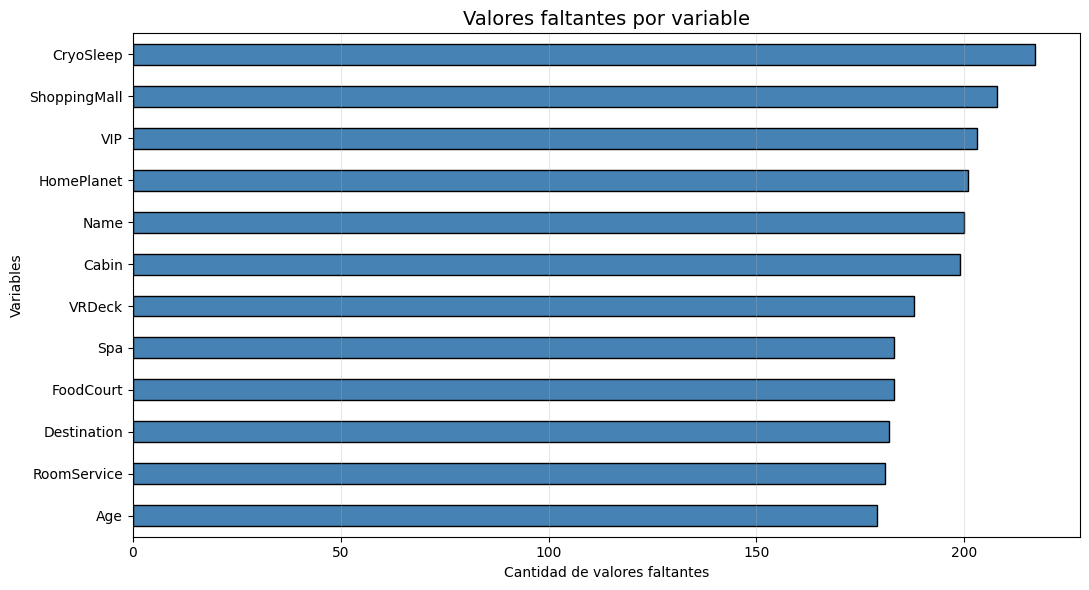

In [12]:
# =====================================================
#  — GRÁFICA DE VALORES NULOS
# =====================================================

# Calcular valores nulos
nulos = df_train.isnull().sum()

# Conservar únicamente columnas con nulos
nulos = nulos[nulos > 0].sort_values()

# Crear gráfica
plt.figure(figsize=(11, 6))

nulos.plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

plt.title(
    "Valores faltantes por variable",
    fontsize=14
)

plt.xlabel("Cantidad de valores faltantes")
plt.ylabel("Variables")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

La grafica muestra la cantidad de valores faltantes que presenta cada variable de nuestro conjunto de entrenamiento.

observamos que CryoSleep tiene la mayor cantidad de datos faltantes,  con 217 registros seguida de ShoppingMall con 208 y VIP con 203. Por otra parte, Age presenta la menor cantidad, con 179 registros.

En general, los valores faltantes representan porcentajes bajos respecto al total de 8,693 pasajeros, ya que ninguna variable supera el 2.5%.

Sin embargo, anteriormente identificamos que el 24.01% de los pasajeros tiene al menos un dato faltante. Por lo tanto, eliminar directamente estos registros provocaría una pérdida considerable de información.

Consideramos que lo más conveniente es evaluar métodos de imputación de acuerdo con el tipo de variable, buscando conservar la mayor cantidad posible de datos para el entrenamiento de nuestra red neuronal.

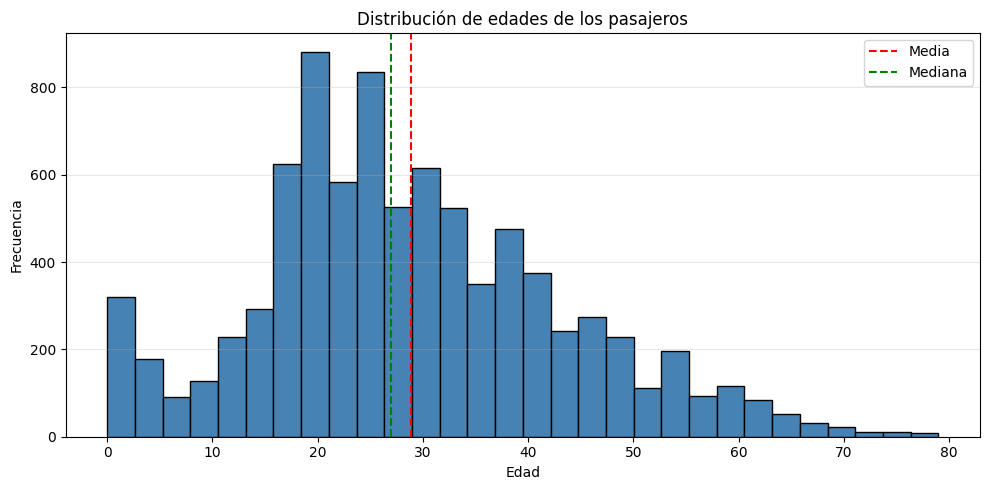

In [13]:
# =====================================================
#  DISTRIBUCIÓN DE EDADES
# =====================================================

plt.figure(figsize=(10, 5))

plt.hist(
    df_train["Age"].dropna(),
    bins=30,
    color="steelblue",
    edgecolor="black"
)

plt.axvline(
    df_train["Age"].mean(),
    color="red",
    linestyle="--",
    label="Media"
)

plt.axvline(
    df_train["Age"].median(),
    color="green",
    linestyle="--",
    label="Mediana"
)

plt.title("Distribución de edades de los pasajeros")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Notamos que el histograma muestra la distribucion de las edades de los pasajeros de Spaceship Titanic. Observamos que la mayor concentración de pasajeros se encuentra aproximadamente entre los 18 y 35 años.

La media se sitúa alrededor de los 29 años, mientras que la mediana es de aproximadamente 27 años. Esto indica que la distribución presenta una ligera asimetría positiva, debido a que existen pasajeros con edades más avanzadas que elevan el promedio.

También observamos que la frecuencia disminuye conforme aumentan las edades, especialmente después de los 60 años.

A partir de estos resultados, consideramos que la mediana puede ser una alternativa adecuada para reemplazar los 179 valores faltantes de la variable Age, ya que es menos sensible a los valores extremos que la media.

Por el momento, únicamente identificamos esta posibilidad y conservaremos los datos originales hasta realizar el preprocesamiento del modelo.

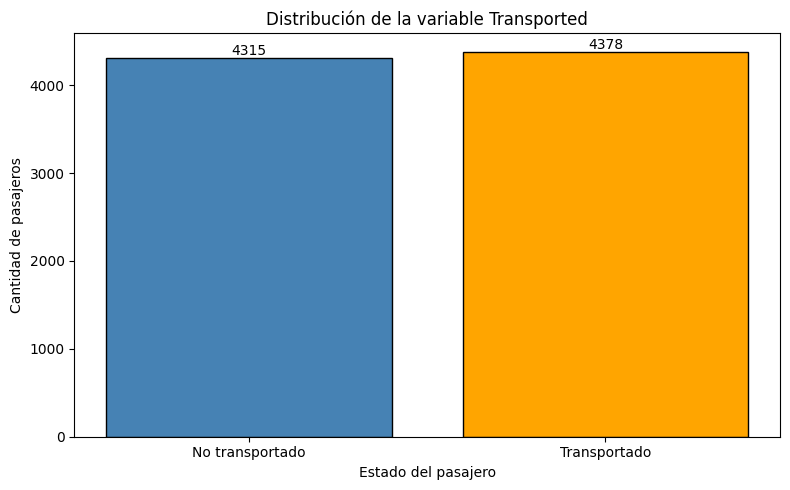

In [14]:
# =====================================================
# DISTRIBUCIÓN DE TRANSPORTED
# =====================================================

frecuencias = (
    df_train["Transported"]
    .value_counts()
    .reindex([False, True])
)

plt.figure(figsize=(8, 5))

plt.bar(
    ["No transportado", "Transportado"],
    frecuencias.values,
    color=["steelblue", "orange"],
    edgecolor="black"
)

plt.title("Distribución de la variable Transported")
plt.xlabel("Estado del pasajero")
plt.ylabel("Cantidad de pasajeros")

for i, valor in enumerate(frecuencias.values):
    plt.text(
        i,
        valor + 30,
        str(valor),
        ha="center"
    )

plt.tight_layout()
plt.show()

### **Interpretación de la distribución de la variable Transported**

La gráfica muestra la distribución de nuestra variable objetivo `Transported`, que indica si un pasajero fue transportado a otra dimensión.

De los 8,693 pasajeros, 4,378 fueron transportados, lo que representa el 50.36%, mientras que 4,315 no fueron transportados, equivalentes al 49.64%.

Observamos que existe una diferencia de únicamente 63 pasajeros entre ambas categorías, por lo que podemos considerar que **nuestra variable objetivo se encuentra balanceada**.

Este resultado es favorable para el entrenamiento de nuestra red neuronal, ya que contamos con cantidades similares de ejemplos de ambas clases.

Por lo tanto, inicialmente no será necesario aplicar técnicas de balanceo de clases. Sin embargo, será importante evaluar el desempeño del modelo utilizando métricas como accuracy, precisión, recall, F1-score y matriz de confusión.

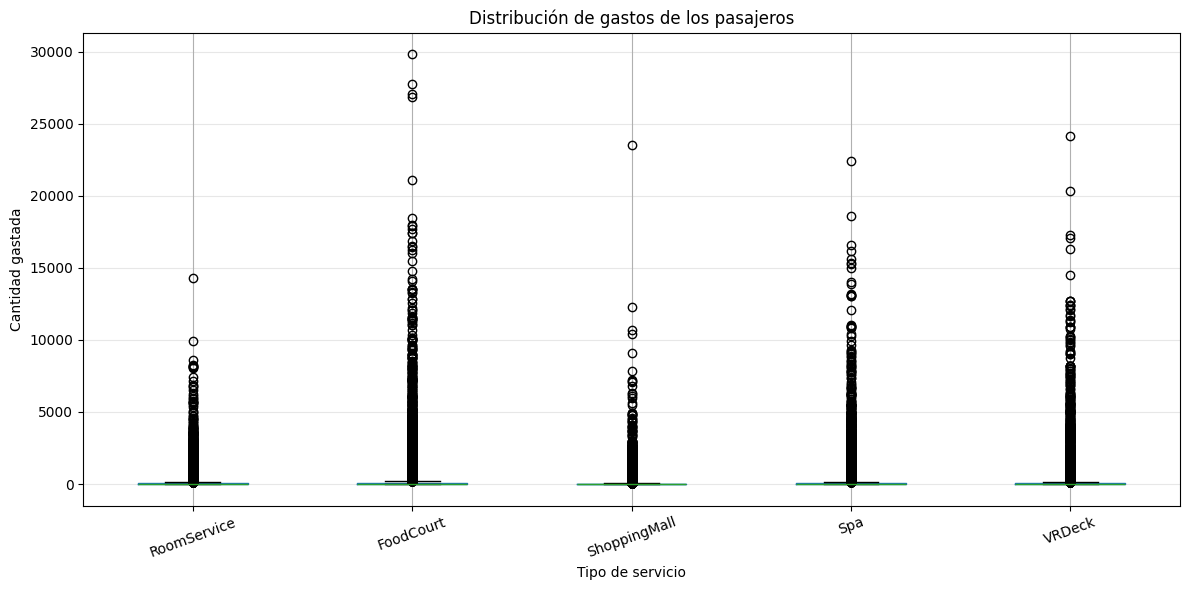

In [15]:
# =====================================================
# - ANÁLISIS DE GASTOS
# =====================================================

columnas_gastos = [
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck"
]

plt.figure(figsize=(12, 6))

df_train[columnas_gastos].boxplot()

plt.title("Distribución de gastos de los pasajeros")
plt.xlabel("Tipo de servicio")
plt.ylabel("Cantidad gastada")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### **Interpretación de la distribución de gastos**

La gráfica muestra la distribución de los gastos realizados por los pasajeros en cinco servicios: RoomService, FoodCourt, ShoppingMall, Spa y VRDeck.

Observamos que la mayoría de los gastos se concentra en valores bajos, cercanos a cero. Sin embargo, también existen pasajeros que realizaron gastos considerablemente elevados, lo que provoca que las distribuciones presenten una asimetría hacia la derecha.

El servicio FoodCourt registra los valores máximos más altos, alcanzando aproximadamente 30,000 unidades, mientras que las demás categorías también presentan gastos elevados.

Además, identificamos numerosos valores atípicos en las cinco variables. Esto no significa necesariamente que sean errores, ya que podrían representar comportamientos reales de consumo.

Estos resultados son importantes para nuestro proyecto porque las diferencias de escala y los valores extremos pueden influir en el entrenamiento de la red neuronal. Por lo tanto, será necesario evaluar métodos de transformación y escalamiento de las variables numéricas antes de construir el modelo.

### **¿Los pasajeros que estuvieron en criosueño tienen una mayor probabilidad de ser transportados a otra dimensión?**

## Objetivo

Analizar si la proporción de pasajeros transportados es diferente entre aquellos que estuvieron en criosueño y aquellos que no, con la finalidad de determinar si `CryoSleep` podría ser una variable relevante para nuestro modelo de clasificación.

## Planteamiento de hipótesis

**Hipótesis nula (H₀):**

No existe una diferencia en la proporción de pasajeros transportados entre quienes estuvieron en criosueño y quienes no estuvieron.

**Hipótesis alternativa (H₁):**

Existe una diferencia en la proporción de pasajeros transportados entre quienes estuvieron en criosueño y quienes no estuvieron.

### Hipótesis matemáticas

\[
H_0: P(T=1\mid C=1)=P(T=1\mid C=0)
\]

\[
H_1: P(T=1\mid C=1)\neq P(T=1\mid C=0)
\]

Donde:

- **T = 1:** el pasajero fue transportado.
- **C = 1:** el pasajero estuvo en criosueño.
- **C = 0:** el pasajero no estuvo en criosueño.

### Metodología

Para analizar esta relación construiremos una tabla de contingencia que muestre las frecuencias absolutas y relativas de ambas variables.

Posteriormente, realizaremos una gráfica de barras para comparar el porcentaje de pasajeros transportados en cada grupo.

Finalmente, podremos aplicar una prueba chi-cuadrada de independencia, utilizando un nivel de significancia de α = 0.05, para evaluar si existe evidencia estadística de asociación entre ambas variables.

### Resultado esperado

Esperamos identificar si los pasajeros que estuvieron en criosueño presentan una proporción de transporte diferente respecto a los pasajeros que no estuvieron en ese estado.

Los resultados nos permitirán evaluar si `CryoSleep` podría aportar información útil para predecir la variable objetivo `Transported` en nuestra red neuronal.

In [17]:
# =====================================================
# RELACIÓN ENTRE CRYOSLEEP Y TRANSPORTED
# =====================================================

# Tabla de frecuencias absolutas
tabla_frecuencias = pd.crosstab(
    df_train["CryoSleep"],
    df_train["Transported"]
)

print("TABLA DE FRECUENCIAS")
display(tabla_frecuencias)

# Porcentajes por categoría de CryoSleep
tabla_porcentajes = pd.crosstab(
    df_train["CryoSleep"],
    df_train["Transported"],
    normalize="index"
) * 100

print("PORCENTAJES POR GRUPO")
display(tabla_porcentajes.round(2))

TABLA DE FRECUENCIAS


Transported,False,True
CryoSleep,,
False,3650,1789
True,554,2483


PORCENTAJES POR GRUPO


Transported,False,True
CryoSleep,,
False,67.11,32.89
True,18.24,81.76


### ***Resultado e interpretacion de la hipotesis***

A partir de la tabla contingencia encontramos diferencias imporantes entre los pasajeros que tuvieron en criosueño y aquellos que no.

De los 5439 pasajeros que no estuvieron en criosueño, solamnete el 32.89% pasajeros fue trasportado pasajeros que sí estuvieron en criosueño, el 81.76% fue transportado.

La diferencia entre ambos grupos es de 48.87 puntos porcentuales, lo que indica una asociación importante entre las variables.

Para evaluar nuestra hipótesis aplicamos una prueba chi-cuadrada de independencia, obteniendo un estadístico de aproximadamente 1,859.61 y un valor p menor que 0.001.

Como el valor p es inferior al nivel de significancia de 0.05, rechazamos la hipótesis nula.

Conclusión: Existe evidencia estadística de una asociación entre CryoSleep y Transported. Los pasajeros que estuvieron en criosueño presentan una proporción significativamente mayor de transporte.

Estos resultados sugieren que CryoSleep puede ser una variable importante para nuestro modelo de Machine Learning. Sin embargo, todavía tendremos que evaluar su contribución predictiva durante el entrenamiento y la validación de nuestra red neuronal.

In [19]:

chi2, p, gl, esperados = chi2_contingency(
    tabla_frecuencias
)

print(f"Chi-cuadrada: {chi2:.4f}")
print(f"Valor p: {p:.4e}")
print(f"Grados de libertad: {gl}")

if p < 0.05:
    print("Se rechaza H0")
else:
    print("No se rechaza H0")

Chi-cuadrada: 1859.6127
Valor p: 0.0000e+00
Grados de libertad: 1
Se rechaza H0


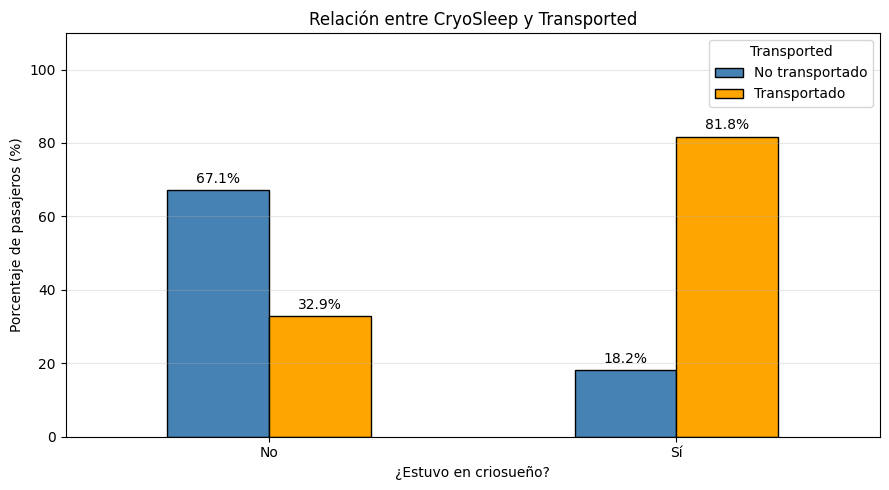

In [18]:
# =====================================================
# GRÁFICA — CRYOSLEEP VS TRANSPORTED
# =====================================================


ax = tabla_porcentajes.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange"],
    edgecolor="black"
)

plt.title("Relación entre CryoSleep y Transported")
plt.xlabel("¿Estuvo en criosueño?")
plt.ylabel("Porcentaje de pasajeros (%)")

plt.xticks(
    ticks=[0, 1],
    labels=["No", "Sí"],
    rotation=0
)

plt.legend(
    ["No transportado", "Transportado"],
    title="Transported"
)

plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.3)

for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

### Interpretación de la relación entre CryoSleep y Transported

La gráfica permite comparar el porcentaje de pasajeros transportados según su estado de criosueño.

Observamos que, entre los pasajeros que no estuvieron en criosueño, el 67.1% no fue transportado y solamente el 32.9% sí lo fue.

En cambio, entre los pasajeros que estuvieron en criosueño, el 81.8% fue transportado y el 18.2% no.

Estos resultados muestran una diferencia de aproximadamente 48.9 puntos porcentuales entre ambos grupos, lo que indica una asociación importante entre las variables `CryoSleep` y `Transported`.

Además, mediante la prueba chi-cuadrada encontramos evidencia estadísticamente significativa de esta asociación, con un valor p menor que 0.001.

Por lo tanto, rechazamos la hipótesis nula de independencia entre ambas variables.

**Conclusión:** Los pasajeros que estuvieron en criosueño presentan una mayor proporción de transporte. Esto sugiere que `CryoSleep` podría ser una variable predictiva relevante para nuestra red neuronal, aunque será necesario comprobar su utilidad durante la evaluación del modelo.

## Análisis de la relación entre HomePlanet y Transported

### Pregunta de investigación

¿La proporción de pasajeros transportados a otra dimensión cambia dependiendo de su planeta de origen?

### Objetivo

Analizar la relación entre el planeta de origen de los pasajeros y su estado de transporte, para identificar si `HomePlanet` podría ser una variable relevante para nuestro modelo de Machine Learning.

### Hipótesis nula (H₀)

La proporción de pasajeros transportados es igual para los pasajeros provenientes de Earth, Europa y Mars.

### Hipótesis alternativa (H₁)

Al menos uno de los planetas presenta una proporción de pasajeros transportados diferente a los demás.

### Hipótesis matemáticas

\[
H_0:p_{\text{Earth}}=p_{\text{Europa}}=p_{\text{Mars}}
\]

\[
H_1:\text{Al menos una proporción es diferente}
\]

Donde cada proporción representa la probabilidad de ser transportado entre los pasajeros de un determinado planeta.

### Metodología

Se construirá una tabla de contingencia para obtener las frecuencias absolutas y los porcentajes de transporte por planeta.

Posteriormente, se realizará una gráfica de barras para comparar las proporciones y se aplicará una prueba chi-cuadrada de independencia con un nivel de significancia de 0.05.

Este análisis permitirá evaluar si existe evidencia estadística de una asociación entre `HomePlanet` y `Transported`.

In [21]:
# =====================================================
#  — HOMEPLANET VS TRANSPORTED
# =====================================================


# Tabla de frecuencias absolutas
tabla_planeta = pd.crosstab(
    df_train["HomePlanet"],
    df_train["Transported"]
)

print("TABLA DE FRECUENCIAS")
display(tabla_planeta)

# Porcentajes por planeta de origen
tabla_planeta_pct = pd.crosstab(
    df_train["HomePlanet"],
    df_train["Transported"],
    normalize="index"
) * 100

print("\nPORCENTAJES POR PLANETA")
display(tabla_planeta_pct.round(2))

TABLA DE FRECUENCIAS


Transported,False,True
HomePlanet,,
Earth,2651,1951
Europa,727,1404
Mars,839,920



PORCENTAJES POR PLANETA


Transported,False,True
HomePlanet,,
Earth,57.61,42.39
Europa,34.12,65.88
Mars,47.70,52.30


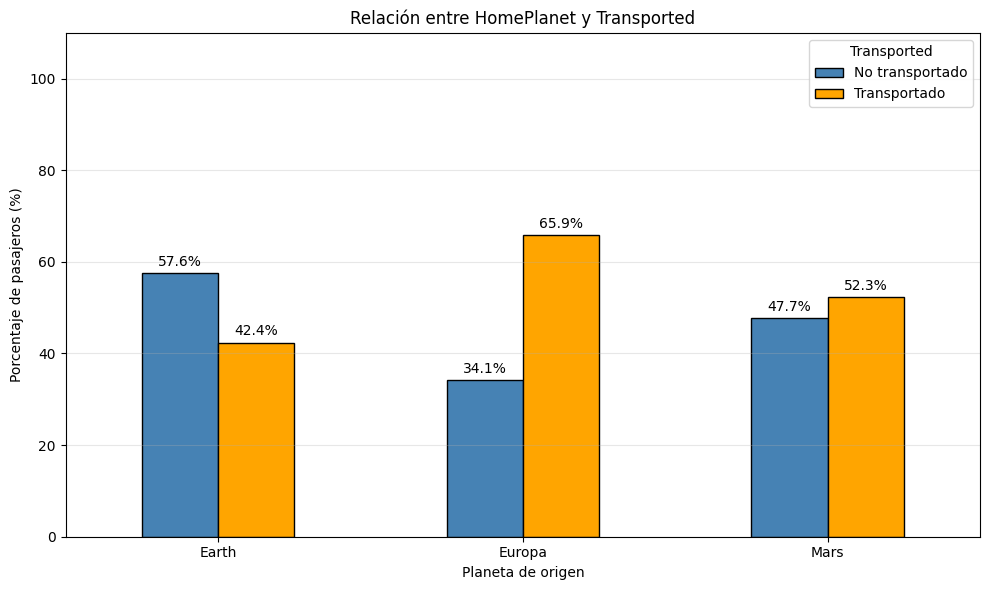

In [22]:
# =====================================================
# GRÁFICA — HOMEPLANET VS TRANSPORTED
# =====================================================


ax = tabla_planeta_pct.plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "orange"],
    edgecolor="black"
)

plt.title("Relación entre HomePlanet y Transported")
plt.xlabel("Planeta de origen")
plt.ylabel("Porcentaje de pasajeros (%)")

plt.xticks(rotation=0)

plt.legend(
    ["No transportado", "Transportado"],
    title="Transported"
)

plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.3)

# Agregar porcentajes a las barras
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

In [23]:
# =====================================================
# PRUEBA CHI-CUADRADA
# =====================================================

chi2, p, gl, esperados = chi2_contingency(
    tabla_planeta
)

print(f"Chi-cuadrada: {chi2:.4f}")
print(f"Valor p: {p:.6e}")
print(f"Grados de libertad: {gl}")

if p < 0.05:
    print("Se rechaza H0: existe asociación estadística.")
else:
    print("No se rechaza H0: evidencia insuficiente.")

Chi-cuadrada: 324.9014
Valor p: 2.809060e-71
Grados de libertad: 2
Se rechaza H0: existe asociación estadística.


### Interpretación de la relación entre HomePlanet y Transported

Al analizar la relación entre el planeta de origen y el estado de transporte de los pasajeros, encontramos diferencias importantes entre las tres categorías.

Los pasajeros provenientes de Europa presentan la mayor proporción de transporte, con un 65.88%, seguidos de Mars con un 52.30%. Por otra parte, Earth registra la menor proporción, con un 42.39%.

La diferencia entre Europa y Earth es de 23.49 puntos porcentuales, lo que indica que el comportamiento del transporte no es igual entre los distintos planetas.

Para evaluar esta relación aplicamos una prueba chi-cuadrada de independencia, obteniendo un estadístico de 324.9014 y un valor p de aproximadamente 2.81 × 10⁻⁷¹.

Como el valor p es menor que nuestro nivel de significancia de 0.05, rechazamos la hipótesis nula.

**Conclusión:** Existe evidencia estadísticamente significativa de una asociación entre `HomePlanet` y `Transported`. Los pasajeros provenientes de Europa presentan la mayor proporción de transporte, mientras que los provenientes de Earth presentan la menor.

Estos resultados sugieren que `HomePlanet` puede aportar información relevante para nuestro modelo de clasificación. Sin embargo, será necesario comprobar su utilidad predictiva durante el entrenamiento y la validación de la red neuronal.

##  — Relación entre los gastos y Transported

### Pregunta de investigación

¿Los pasajeros que fueron transportados presentan un comportamiento de gasto diferente respecto a los pasajeros que no fueron transportados?

### Objetivo

Analizar la distribución de los gastos de los pasajeros para identificar posibles diferencias entre las categorías de `Transported` y determinar si estas variables podrían aportar información relevante para nuestro modelo de clasificación.

### Hipótesis

**Hipótesis nula (H₀):** La distribución del gasto total es igual entre los pasajeros transportados y no transportados.

**Hipótesis alternativa (H₁):** La distribución del gasto total es diferente entre ambos grupos.

### Metodología

Se calculará el gasto total de cada pasajero considerando los cinco servicios disponibles: RoomService, FoodCourt, ShoppingMall, Spa y VRDeck.

Posteriormente, se compararán las estadísticas descriptivas y las distribuciones de ambos grupos mediante gráficas.

Finalmente, se podrá aplicar una prueba estadística para evaluar si existen diferencias significativas entre las distribuciones.

In [24]:
# =====================================================
# CREACIÓN DE TOTALGASTOS
# =====================================================

columnas_gastos = [
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck"
]

# Crear una copia para no modificar nuestra base original
df_eda = df_train.copy()

# Identificar filas con todos los gastos disponibles
gastos_completos = df_eda[columnas_gastos].notna().all(axis=1)

# Sumar únicamente cuando los cinco gastos están disponibles
df_eda["TotalGastos"] = df_eda[columnas_gastos].sum(
    axis=1,
    min_count=5
)

print("Registros con los cinco gastos disponibles:",
      gastos_completos.sum())

print("Registros con gasto total incompleto:",
      df_eda["TotalGastos"].isna().sum())

display(df_eda[["TotalGastos", "Transported"]].head(10))

Registros con los cinco gastos disponibles: 7785
Registros con gasto total incompleto: 908


,TotalGastos,Transported
0,0.0,False
1,736.0,True
2,10383.0,False
3,5176.0,False
4,1091.0,True
5,774.0,True
6,1584.0,True
7,NaN,True
8,1018.0,True
9,0.0,True


In [25]:
# =====================================================
# ESTADÍSTICAS DE GASTO SEGÚN TRANSPORTED
# =====================================================

resumen_gastos = (
    df_eda.groupby("Transported")["TotalGastos"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

display(resumen_gastos)

,count,mean,median,std,min,max
Transported,,,,,,
False,3873,2049.82,914.0,3169.56,0.0,35987.0
True,3912,925.02,0.0,2353.12,0.0,31076.0


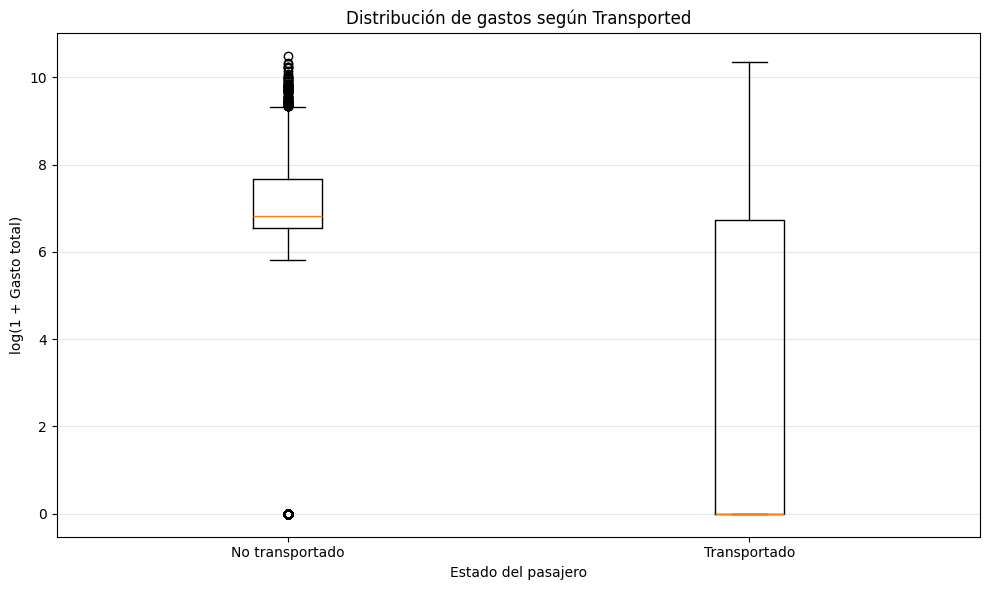

In [29]:
# =====================================================
# GRÁFICA — TOTALGASTOS VS TRANSPORTED
# =====================================================



# Separar los dos grupos
gastos_no = df_eda.loc[
    df_eda["Transported"] == False,
    "TotalGastos"
].dropna()

gastos_si = df_eda.loc[
    df_eda["Transported"] == True,
    "TotalGastos"
].dropna()

# Transformación logarítmica
datos = [
    np.log1p(gastos_no),
    np.log1p(gastos_si)
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    datos,
    tick_labels=["No transportado", "Transportado"]
)

plt.title("Distribución de gastos según Transported")
plt.xlabel("Estado del pasajero")
plt.ylabel("log(1 + Gasto total)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Resultados e interpretación de la relación entre gastos y Transported

Para analizar la relación entre los gastos y el estado de transporte, construimos una nueva variable llamada `TotalGastos`, que representa la suma de los consumos realizados en RoomService, FoodCourt, ShoppingMall, Spa y VRDeck.

De los 8,693 pasajeros, encontramos que 7,785 tienen información completa en las cinco variables de gastos, mientras que 908 presentan al menos un valor faltante.

Al comparar ambos grupos, observamos que los pasajeros no transportados tienen un gasto promedio de 2,049.82 unidades, mientras que los pasajeros transportados presentan un promedio de 925.02 unidades.

También encontramos una diferencia importante en las medianas. Los pasajeros no transportados presentan una mediana de 914 unidades, mientras que los transportados tienen una mediana de cero. Esto significa que al menos la mitad de los pasajeros transportados con información completa no registró gastos en los servicios analizados.

Por otra parte, ambos grupos presentan valores extremos, aunque los pasajeros no transportados muestran una mayor desviación estándar.

La gráfica de cajas confirma que las distribuciones de gastos son diferentes, destacando una concentración de valores iguales a cero entre los pasajeros transportados.

### Conclusión

Los resultados descriptivos sugieren una asociación entre el gasto total y la variable `Transported`. Los pasajeros transportados tienden a registrar gastos menores que aquellos que no fueron transportados.

Por lo tanto, consideramos que las variables de gastos podrían aportar información relevante para nuestra red neuronal.

Sin embargo, todavía necesitamos evaluar estadísticamente esta relación y comprobar su capacidad predictiva mediante el entrenamiento y la validación del modelo.

### ***Matriz de correlación***

## Análisis de correlación

### Pregunta de investigación

¿Qué relaciones lineales existen entre las variables numéricas del conjunto de datos y cuáles presentan una mayor asociación con la variable objetivo `Transported`?

### Objetivo

Identificar relaciones entre la edad, los gastos de los pasajeros y el estado de transporte, utilizando una matriz de correlación de Pearson.

Este análisis nos permitirá explorar posibles asociaciones positivas y negativas, así como identificar variables que contienen información relacionada entre sí.

### Metodología

Se seleccionaron las variables numéricas del conjunto de entrenamiento y se incorporó la variable `Transported`, codificada como 0 para los pasajeros no transportados y 1 para los transportados.

Posteriormente, se calculó una matriz de correlación de Pearson y se representaron los coeficientes mediante un mapa de calor.

Los resultados permitirán identificar relaciones lineales que podrían ser relevantes durante la preparación de las variables para nuestra red neuronal.

MATRIZ DE CORRELACIÓN


,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TotalGastos,Transported
Age,1.000,0.069,0.130,0.033,0.124,0.101,0.189,-0.075
RoomService,0.069,1.000,-0.016,0.054,0.010,-0.020,0.236,-0.245
FoodCourt,0.130,-0.016,1.000,-0.014,0.222,0.228,0.747,0.047
ShoppingMall,0.033,0.054,-0.014,1.000,0.014,-0.007,0.224,0.010
Spa,0.124,0.010,0.222,0.014,1.000,0.154,0.598,-0.221
VRDeck,0.101,-0.020,0.228,-0.007,0.154,1.000,0.573,-0.207
TotalGastos,0.189,0.236,0.747,0.224,0.598,0.573,1.000,-0.198
Transported,-0.075,-0.245,0.047,0.010,-0.221,-0.207,-0.198,1.000


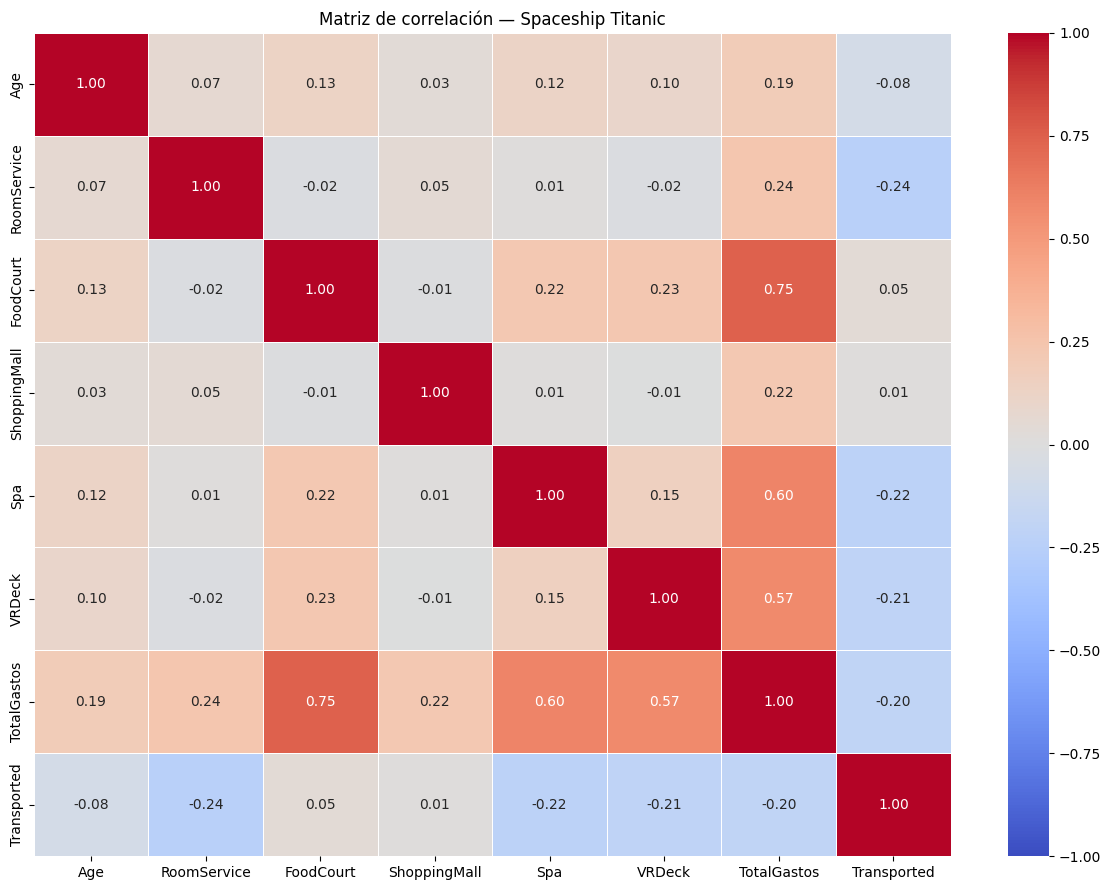

In [32]:
# =====================================================
#  MATRIZ DE CORRELACIÓN
# =====================================================


# Seleccionar variables
variables = [
    "Age",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "TotalGastos"
]

# Crear copia para el análisis
df_corr = df_eda[variables + ["Transported"]].copy()

# Convertir Transported a variable binaria
df_corr["Transported"] = (
    df_corr["Transported"].astype(int)
)

# Calcular correlaciones de Pearson
matriz_corr = df_corr.corr(method="pearson")

print("MATRIZ DE CORRELACIÓN")
display(matriz_corr.round(3))

# Visualización
plt.figure(figsize=(12, 9))

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Matriz de correlación — Spaceship Titanic")
plt.tight_layout()
plt.show()

## Resultados e interpretación de la matriz de correlación

La matriz de correlación permitió analizar las relaciones lineales entre las variables numéricas y nuestra variable objetivo `Transported`.

Encontramos que las variables con las correlaciones negativas de mayor magnitud respecto a `Transported` son `RoomService` (-0.24), `Spa` (-0.22) y `VRDeck` (-0.21).

Estos resultados indican que los pasajeros con mayores gastos en estos servicios tienden a presentar una menor proporción de transporte. Sin embargo, las correlaciones son débiles, por lo que no podemos concluir que estas variables por sí solas permitan realizar predicciones precisas.

Por otra parte, `FoodCourt` (0.05) y `ShoppingMall` (0.01) presentan correlaciones prácticamente nulas con la variable objetivo.

También identificamos una correlación positiva de 0.75 entre `FoodCourt` y `TotalGastos`, seguida de `Spa` (0.60) y `VRDeck` (0.57). Estas relaciones son esperables porque las variables forman parte del cálculo del gasto total.

### Conclusión

Los resultados sugieren que algunas variables de gastos contienen información asociada con el estado de transporte de los pasajeros, aunque sus relaciones lineales individuales son débiles.

Esto no significa que debamos eliminar las variables con correlaciones bajas, ya que podrían presentar relaciones no lineales o interacciones con otras características.

Por lo tanto, consideramos conveniente conservar inicialmente estas variables y evaluar su capacidad predictiva durante el entrenamiento de nuestra red neuronal.

### ***Validacion de duplicados***

## — Validación de calidad de datos

### Objetivo

Verificar la calidad y consistencia del conjunto de entrenamiento mediante la identificación de registros duplicados, identificadores repetidos, valores numéricos fuera de rangos esperados y posibles inconsistencias entre variables.

### Preguntas de análisis

- ¿Existen registros duplicados dentro de la base?
- ¿Cada pasajero tiene un identificador único?
- ¿Las edades registradas presentan valores negativos?
- ¿Existen gastos negativos?
- ¿Los pasajeros que estuvieron en criosueño presentan consumos registrados?

### Metodología

Se utilizarán funciones de Pandas para identificar duplicados y validar los rangos de las variables numéricas.

Además, se analizará la relación entre `CryoSleep` y las variables de gastos para identificar registros que podrían presentar inconsistencias.

Este proceso permitirá evaluar si nuestra base contiene errores que deban corregirse antes del entrenamiento del modelo de Machine Learning.

In [33]:
# =====================================================
# — VALIDACIÓN DE DUPLICADOS
# =====================================================

print("=" * 55)
print("ANÁLISIS DE REGISTROS DUPLICADOS")
print("=" * 55)

# Duplicados exactos
duplicados_exactos = df_train.duplicated().sum()

# Identificadores repetidos
duplicados_id = df_train["PassengerId"].duplicated().sum()

# Identificadores únicos
ids_unicos = df_train["PassengerId"].nunique()

print("Total de registros:", len(df_train))
print("Duplicados exactos:", duplicados_exactos)
print("PassengerId duplicados:", duplicados_id)
print("PassengerId únicos:", ids_unicos)

ANÁLISIS DE REGISTROS DUPLICADOS
Total de registros: 8693
Duplicados exactos: 0
PassengerId duplicados: 0
PassengerId únicos: 8693


In [34]:
# =====================================================
# VALIDACIÓN DE VARIABLES NUMÉRICAS
# =====================================================

columnas_gastos = [
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck"
]

print("=" * 55)
print("VALIDACIÓN DE EDAD")
print("=" * 55)

print("Edad mínima:", df_train["Age"].min())
print("Edad máxima:", df_train["Age"].max())
print("Edades negativas:", (df_train["Age"] < 0).sum())

print("\n" + "=" * 55)
print("VALIDACIÓN DE GASTOS")
print("=" * 55)

for columna in columnas_gastos:
    negativos = (df_train[columna] < 0).sum()

    print(
        f"{columna}: "
        f"Mínimo={df_train[columna].min():.2f}, "
        f"Máximo={df_train[columna].max():.2f}, "
        f"Negativos={negativos}"
    )

VALIDACIÓN DE EDAD
Edad mínima: 0.0
Edad máxima: 79.0
Edades negativas: 0

VALIDACIÓN DE GASTOS
RoomService: Mínimo=0.00, Máximo=14327.00, Negativos=0
FoodCourt: Mínimo=0.00, Máximo=29813.00, Negativos=0
ShoppingMall: Mínimo=0.00, Máximo=23492.00, Negativos=0
Spa: Mínimo=0.00, Máximo=22408.00, Negativos=0
VRDeck: Mínimo=0.00, Máximo=24133.00, Negativos=0


In [35]:
# =====================================================
# VALIDACIÓN — CRYOSLEEP Y GASTOS
# =====================================================

# Copia de trabajo
df_validacion = df_train.copy()

# Identificar pasajeros con CryoSleep=True
en_criosueno = df_validacion["CryoSleep"].eq(True)

# Identificar gastos positivos registrados
gastos_positivos = (
    df_validacion[columnas_gastos] > 0
).any(axis=1)

# Pasajeros en criosueño con algún gasto positivo
inconsistencias = df_validacion[
    en_criosueno & gastos_positivos
]

print("Pasajeros en criosueño:",
      en_criosueno.sum())

print("Pasajeros en criosueño con gastos positivos:",
      len(inconsistencias))

display(
    inconsistencias[
        ["PassengerId", "CryoSleep"] + columnas_gastos
    ].head(10)
)

Pasajeros en criosueño: 3037
Pasajeros en criosueño con gastos positivos: 0


,PassengerId,CryoSleep,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck


## Resultados de la validación de calidad de datos

Se realizó una revisión de la calidad del conjunto de entrenamiento para identificar registros duplicados, valores fuera de rangos esperados y posibles inconsistencias entre variables.

Primero, encontramos que los 8,693 registros tienen identificadores únicos y que no existen filas duplicadas.

En cuanto a la variable `Age`, observamos edades entre 0 y 79 años, sin valores negativos. Esto indica que no encontramos edades imposibles mediante el criterio utilizado.

También analizamos las cinco variables de gastos y comprobamos que ninguna presenta valores negativos. Aunque existen gastos elevados, estos no necesariamente representan errores en la información.

Finalmente, analizamos la relación entre `CryoSleep` y los gastos. De los 3,037 pasajeros que estuvieron en criosueño, ninguno presenta gastos positivos registrados en los servicios analizados.

### Conclusión

Los resultados muestran que nuestra base presenta una buena consistencia inicial, ya que no identificamos registros duplicados, edades negativas, gastos negativos ni pasajeros en criosueño con gastos positivos.

Sin embargo, todavía existen valores faltantes que deberán tratarse durante el preprocesamiento.

Por lo tanto, consideramos que la base tiene condiciones adecuadas para continuar con la preparación de los datos y posteriormente entrenar nuestra red neuronal.

In [36]:
# = — VALIDACIÓN TRAIN VS TEST

variables_train = set(df_train.columns) - {"Transported"}
variables_test = set(df_test.columns)

print("Variables exclusivas de train:",
      variables_train - variables_test)

print("Variables exclusivas de test:",
      variables_test - variables_train)

print("\nVALORES NULOS EN TEST")
display(df_test.isnull().sum())

print("\nCATEGORÍAS EN TRAIN Y TEST")

for columna in ["HomePlanet", "Destination", "CryoSleep", "VIP"]:
    train_cat = set(df_train[columna].dropna().unique())
    test_cat = set(df_test[columna].dropna().unique())

    print(f"\n{columna}")
    print("Categorías nuevas en test:", test_cat - train_cat)

Variables exclusivas de train: set()
Variables exclusivas de test: set()

VALORES NULOS EN TEST


,0
PassengerId,0
HomePlanet,87
CryoSleep,93
Cabin,100
Destination,92
Age,91
VIP,93
RoomService,82
FoodCourt,106
ShoppingMall,98



CATEGORÍAS EN TRAIN Y TEST

HomePlanet
Categorías nuevas en test: set()

Destination
Categorías nuevas en test: set()

CryoSleep
Categorías nuevas en test: set()

VIP
Categorías nuevas en test: set()


### Validación final de las bases de entrenamiento y prueba

Se compararon las estructuras de las bases `train.csv` y `test.csv` para verificar que ambas contienen las mismas variables predictoras.

Los resultados muestran que no existen diferencias en los nombres de las variables, lo cual es importante porque nuestro modelo deberá utilizar la misma información durante el entrenamiento y las predicciones finales.

También identificamos valores faltantes en distintas columnas de la base de prueba. Las variables con mayor cantidad de valores nulos son `FoodCourt`, `Spa` y `Cabin`.

Por otra parte, comprobamos que no existen categorías nuevas en las variables `HomePlanet`, `Destination`, `CryoSleep` y `VIP`.

**Conclusión:** Las bases tienen estructuras compatibles para desarrollar nuestro modelo de clasificación. Sin embargo, todavía requieren un proceso de imputación, codificación de variables categóricas y escalamiento de las variables numéricas antes de entrenar la red neuronal.

### ***División en entrenamiento y validación***

##  Preparación de los datos

### Separación de variables y conjuntos de entrenamiento

Una vez finalizado el análisis exploratorio, comenzamos la preparación de los datos para entrenar nuestra red neuronal artificial.

Primero separamos las variables predictoras (X) de nuestra variable objetivo (`Transported`), la cual convertimos en valores binarios: 0 para los pasajeros no transportados y 1 para los transportados.

Posteriormente, dividimos los 8,693 registros disponibles en dos conjuntos: 80% para entrenamiento y 20% para validación.

Utilizamos una división estratificada para mantener proporciones similares de pasajeros transportados y no transportados en ambos conjuntos. También establecimos una semilla aleatoria de 42 para obtener resultados reproducibles.

Esta división nos permitirá entrenar el modelo con un conjunto de observaciones y evaluar posteriormente su desempeño con datos que no utilizó durante el ajuste de sus parámetros.

El archivo `test.csv` se conservará separado para generar las predicciones finales.

In [42]:
# =====================================================
# SEPARACIÓN DE VARIABLES X e y
# =====================================================

# Variables predictoras
X = df_train.drop(columns=["Transported"]).copy()

# Variable objetivo
y = df_train["Transported"].astype(int).copy()

# Base de prueba final
X_test_final = df_test.copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Dimensiones de test:", X_test_final.shape)

print("\nDistribución de la variable objetivo:")
display(y.value_counts())

Dimensiones de X: (8693, 13)
Dimensiones de y: (8693,)
Dimensiones de test: (4277, 13)

Distribución de la variable objetivo:


,count
Transported,
1,4378
0,4315


In [44]:
# =====================================================
#  DIVISIÓN TRAIN / VALIDACIÓN
# =====================================================

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 55)
print("RESULTADOS DE LA DIVISIÓN")
print("=" * 55)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

print("\nDistribución de clases en entrenamiento:")
display(y_train.value_counts(normalize=True) * 100)

print("\nDistribución de clases en validación:")
display(y_val.value_counts(normalize=True) * 100)

RESULTADOS DE LA DIVISIÓN
X_train: (6954, 13)
X_val: (1739, 13)
y_train: (6954,)
y_val: (1739,)

Distribución de clases en entrenamiento:


,proportion
Transported,
1,50.359505
0,49.640495



Distribución de clases en validación:


,proportion
Transported,
1,50.373778
0,49.626222


##  — División de los datos

Se dividió el conjunto de entrenamiento original en dos subconjuntos, utilizando el 80% de los registros para entrenamiento y el 20% para validación.

Como resultado, obtuvimos 6,954 observaciones para entrenamiento y 1,739 para validación, conservando las 13 variables predictoras originales.

Se utilizó una división estratificada mediante `stratify=y`, con la finalidad de mantener proporciones similares de nuestra variable objetivo `Transported`.

Los resultados muestran que en entrenamiento el 50.36% de los pasajeros fue transportado, mientras que en validación el porcentaje fue de 50.37%.

Esto confirma que la distribución de las clases se mantiene prácticamente igual en ambos conjuntos.

**Conclusión:** La división se realizó correctamente y los conjuntos están preparados para continuar con el tratamiento de valores faltantes y la transformación de variables antes de entrenar nuestra red neuronal.

### **Ingeniería de características**

In [45]:
# =====================================================
# — INGENIERÍA DE CARACTERÍSTICAS
# =====================================================

def crear_caracteristicas(df):

    df = df.copy()

    # 1. Extraer información de Cabin
    cabin = df["Cabin"].str.split("/", expand=True)

    df["Deck"] = cabin[0]
    df["CabinNum"] = pd.to_numeric(
        cabin[1], errors="coerce"
    )
    df["Side"] = cabin[2]

    # 2. Extraer información de PassengerId
    pasajero = df["PassengerId"].str.split(
        "_", expand=True
    )

    df["GroupId"] = pasajero[0]

    df["GroupPosition"] = pd.to_numeric(
        pasajero[1], errors="coerce"
    )

    # Tamaño del grupo calculado en cada conjunto.
    # Para evitar esta dependencia entre particiones,
    # aquí no lo incorporamos todavía.

    # 3. Eliminar columnas originales
    df = df.drop(
        columns=[
            "PassengerId",
            "Cabin",
            "Name",
            "GroupId"
        ]
    )

    return df


# Aplicar a los tres conjuntos
X_train_fe = crear_caracteristicas(X_train)
X_val_fe = crear_caracteristicas(X_val)
X_test_fe = crear_caracteristicas(X_test_final)

print("Dimensiones después de ingeniería:")

print("Entrenamiento:", X_train_fe.shape)
print("Validación:", X_val_fe.shape)
print("Prueba:", X_test_fe.shape)

display(X_train_fe.head())

Dimensiones después de ingeniería:
Entrenamiento: (6954, 14)
Validación: (1739, 14)
Prueba: (4277, 14)


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,CabinNum,Side,GroupPosition
3600,Earth,False,TRAPPIST-1e,0.0,False,0.0,0.0,0.0,0.0,0.0,G,630.0,S,4
1262,Earth,True,TRAPPIST-1e,17.0,False,0.0,0.0,0.0,0.0,0.0,G,201.0,S,1
8612,Earth,NaN,PSO J318.5-22,35.0,False,0.0,0.0,0.0,0.0,0.0,G,1483.0,S,1
5075,Europa,True,55 Cancri e,26.0,False,0.0,0.0,0.0,NaN,0.0,D,164.0,S,1
4758,Earth,False,TRAPPIST-1e,13.0,False,0.0,0.0,60.0,1.0,5147.0,G,818.0,P,1


###**Definir el preprocesamiento**

In [47]:
# =====================================================
# PIPELINE DE PREPROCESAMIENTO
# =====================================================

# Variables numéricas
variables_numericas = [
    "Age",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "CabinNum",
    "GroupPosition"
]

# Variables categóricas
variables_categoricas = [
    "HomePlanet",
    "CryoSleep",
    "Destination",
    "VIP",
    "Deck",
    "Side"
]

# Pipeline numérico
pipeline_numerico = Pipeline(
    steps=[
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler())
    ]
)

# Pipeline categórico
pipeline_categorico = Pipeline(
    steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

# Unir transformaciones
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numerico, variables_numericas),
        ("categoricas", pipeline_categorico, variables_categoricas)
    ]
)

print("Preprocesador configurado correctamente.")

Preprocesador configurado correctamente.


### **Aplicar las transformaciones**

In [48]:
# =====================================================
# -APLICACIÓN DEL PREPROCESAMIENTO
# =====================================================

# Ajustar solamente con entrenamiento
X_train_pre = preprocesador.fit_transform(
    X_train_fe
)

# Aplicar transformaciones aprendidas
X_val_pre = preprocesador.transform(
    X_val_fe
)

X_test_pre = preprocesador.transform(
    X_test_fe
)

print("=" * 55)
print("DIMENSIONES DESPUÉS DEL PREPROCESAMIENTO")
print("=" * 55)

print("X_train_pre:", X_train_pre.shape)
print("X_val_pre:", X_val_pre.shape)
print("X_test_pre:", X_test_pre.shape)

# Verificar valores faltantes
print("\nValores NaN después del preprocesamiento:")

print("Entrenamiento:", np.isnan(X_train_pre).sum())
print("Validación:", np.isnan(X_val_pre).sum())
print("Prueba:", np.isnan(X_test_pre).sum())

# Identificar cantidad final de características
numero_entradas = X_train_pre.shape[1]

print("\nNúmero de entradas para la red neuronal:",
      numero_entradas)

DIMENSIONES DESPUÉS DEL PREPROCESAMIENTO
X_train_pre: (6954, 28)
X_val_pre: (1739, 28)
X_test_pre: (4277, 28)

Valores NaN después del preprocesamiento:
Entrenamiento: 0
Validación: 0
Prueba: 0

Número de entradas para la red neuronal: 28


## Resultados del preprocesamiento

Después de aplicar las técnicas de imputación, codificación y escalamiento, obtuvimos tres conjuntos de datos preparados para el entrenamiento y la evaluación de nuestra red neuronal.

El conjunto de entrenamiento contiene 6,954 registros, el de validación 1,739 y el de prueba final 4,277. Los tres cuentan con 28 características numéricas.

También comprobamos que ninguno de los conjuntos presenta valores faltantes después del preprocesamiento.

Esto indica que las transformaciones se aplicaron correctamente y que los datos tienen una estructura compatible con una red neuronal artificial.

El número de características aumentó de 13 variables originales a 28 entradas numéricas debido a las transformaciones de las variables categóricas y a la ingeniería de características.

**Conclusión:** Nuestros datos están preparados para comenzar el entrenamiento de una red neuronal, utilizando 28 características de entrada para predecir la variable objetivo `Transported`.

### **Construcción del modelo**

In [50]:
# =====================================================
#  CONSTRUCCIÓN DE LA RED NEURONAL
# =====================================================

# Reproducibilidad
tf.keras.utils.set_random_seed(42)

# Número de entradas
numero_entradas = X_train_pre.shape[1]

# Construcción del modelo
modelo = keras.Sequential([
    layers.Input(shape=(numero_entradas,)),

    # Primera capa oculta
    layers.Dense(32, activation="relu"),

    # Segunda capa oculta
    layers.Dense(16, activation="relu"),

    # Capa de salida
    layers.Dense(1, activation="sigmoid")
])

# Configuración del entrenamiento
modelo.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Resumen de arquitectura
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,473 (5.75 KB)

 Trainable params: 1,473 (5.75 KB)

 Non-trainable params: 0 (0.00 B)

## Arquitectura de la red neuronal

Se construyó una red neuronal artificial multicapa (MLP) para predecir si un pasajero fue transportado a otra dimensión.

El modelo recibe 28 características numéricas obtenidas durante el preprocesamiento y cuenta con dos capas ocultas: la primera tiene 32 neuronas y la segunda 16. Ambas utilizan la función de activación ReLU.

La capa de salida contiene una neurona con activación sigmoide, debido a que nuestro problema corresponde a una clasificación binaria.

El modelo tiene un total de 1,473 parámetros entrenables, distribuidos entre los pesos y sesgos de las tres capas densas.

Para el entrenamiento se seleccionó el optimizador Adam, con una tasa de aprendizaje de 0.001, y la función de pérdida Binary Crossentropy.

Esta arquitectura será nuestro modelo inicial, cuyo rendimiento evaluaremos posteriormente utilizando los datos de validación.

## **Entrenamiento de nuestra red neuronal**

In [52]:
# =====================================================
# FASE 4.2 — ENTRENAMIENTO DE LA RED NEURONAL
# =====================================================



# Configurar parada anticipada
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Entrenar el modelo
historial = modelo.fit(
    X_train_pre,
    y_train,
    validation_data=(X_val_pre, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("\nEntrenamiento finalizado.")

print(
    "Épocas ejecutadas:",
    len(historial.history["loss"])
)

Epoch 1/100
218/218 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7552 - loss: 0.5137 - val_accuracy: 0.7723 - val_loss: 0.4419
Epoch 2/100
218/218 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7980 - loss: 0.4353 - val_accuracy: 0.7872 - val_loss: 0.4222
Epoch 3/100
218/218 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8031 - loss: 0.4214 - val_accuracy: 0.7901 - val_loss: 0.4130
Epoch 4/100
218/218 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8046 - loss: 0.4137 - val_accuracy: 0.7913 - val_loss: 0.4080
Epoch 5/100
218/218 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8054 - loss: 0.4087 - val_accuracy: 0.7947 - val_loss: 0.4051
Epoch 6/100
218/218 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8076 - loss: 0.4048 - val_accuracy: 0.7987 - val_loss: 0.4031
Epoch 7/100
218/218 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8095 - loss: 0.4014 - val_accuracy: 0.7999 - val_loss: 0.4018
Epoch 8/100
218/218 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8102 - loss: 0.3984 - val_accu

In [53]:
EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [54]:
print("Épocas ejecutadas:", len(historial.history["loss"]))

print(
    "Mejor época:",
    np.argmin(historial.history["val_loss"]) + 1
)

print(
    "Menor pérdida de validación:",
    min(historial.history["val_loss"])
)

Épocas ejecutadas: 25
Mejor época: 15
Menor pérdida de validación: 0.39695626497268677


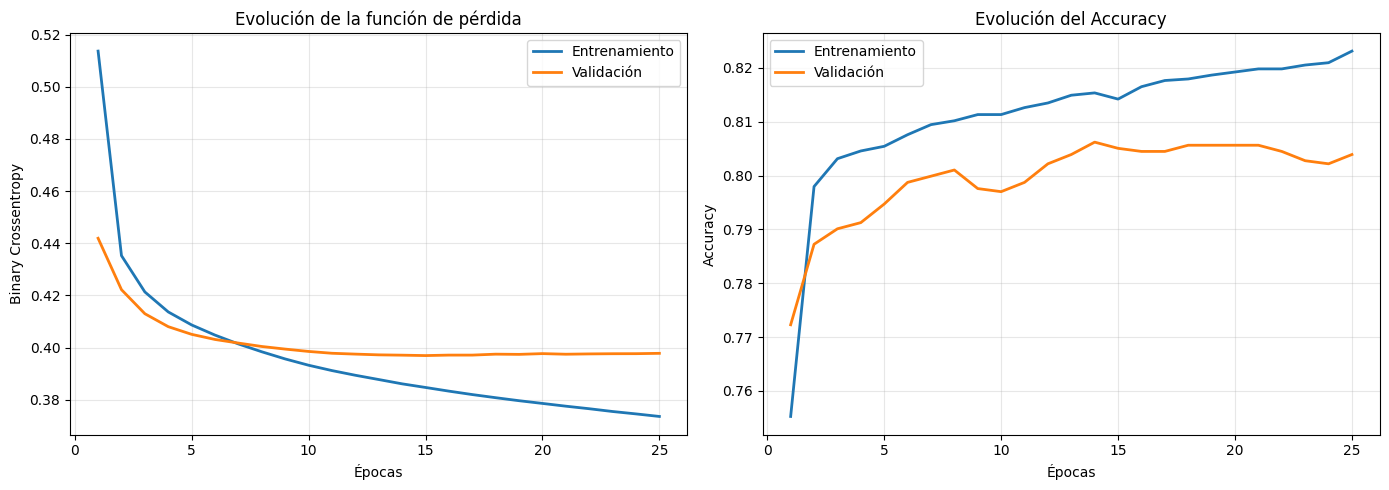

Mejor época según val_loss: 15


In [55]:
# =====================================================
#  — CURVAS DE APRENDIZAJE
# =====================================================

epocas = range(1, len(historial.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# GRÁFICA 1 — PÉRDIDA
axes[0].plot(
    epocas,
    historial.history["loss"],
    label="Entrenamiento",
    linewidth=2
)

axes[0].plot(
    epocas,
    historial.history["val_loss"],
    label="Validación",
    linewidth=2
)

axes[0].set_title("Evolución de la función de pérdida")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# GRÁFICA 2 — ACCURACY
axes[1].plot(
    epocas,
    historial.history["accuracy"],
    label="Entrenamiento",
    linewidth=2
)

axes[1].plot(
    epocas,
    historial.history["val_accuracy"],
    label="Validación",
    linewidth=2
)

axes[1].set_title("Evolución del Accuracy")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Identificar mejor época según val_loss
mejor_epoca = np.argmin(
    historial.history["val_loss"]
) + 1

print("Mejor época según val_loss:", mejor_epoca)

## — Análisis de las curvas de aprendizaje

Las curvas de aprendizaje permiten observar cómo evolucionó el rendimiento de nuestra red neuronal durante las 25 épocas de entrenamiento.

En la gráfica de pérdida observamos que, durante las primeras épocas, tanto el error de entrenamiento como el de validación disminuyeron considerablemente. Esto indica que el modelo comenzó a aprender patrones relevantes de los datos.

Sin embargo, aproximadamente después de la época 15, la pérdida de validación dejó de mejorar, mientras que la pérdida de entrenamiento continuó disminuyendo. Este comportamiento sugiere señales de sobreajuste leve.

En la gráfica de accuracy observamos un comportamiento similar. El modelo alcanzó su mayor accuracy de validación en la época 14, con un 80.62%, mientras que el accuracy de entrenamiento continuó aumentando hasta aproximadamente un 82.31% en la última época.

La diferencia entre ambas curvas indica que el modelo presenta un mejor desempeño sobre los datos de entrenamiento que sobre los datos de validación.

Gracias a Early Stopping, el entrenamiento se detuvo automáticamente en la época 25 y se restauraron los pesos correspondientes a la menor pérdida de validación, registrada en la época 15.

### Conclusión

Nuestra red neuronal logró aprender patrones importantes para clasificar a los pasajeros. Sin embargo, después de las primeras 15 épocas comenzaron a observarse señales de sobreajuste leve.

Por lo tanto, consideramos que la arquitectura inicial presenta un desempeño razonable, aunque todavía es necesario evaluar sus predicciones y comparar diferentes configuraciones para determinar si podemos mejorar su capacidad de generalización.

In [57]:
# =====================================================
# FASE 5.1 — EVALUACIÓN DEL MODELO
# =====================================================

# Probabilidades estimadas por la red neuronal
y_prob = modelo.predict(X_val_pre).ravel()

# Convertir probabilidades en clases
y_pred = (y_prob >= 0.5).astype(int)

# Calcular métricas
accuracy = accuracy_score(y_val, y_pred)
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)

print("=" * 55)
print("EVALUACIÓN DE LA RED NEURONAL")
print("=" * 55)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_val,
    y_pred,
    target_names=["No transportado", "Transportado"]
))

print("\nMATRIZ DE CONFUSIÓN")
print(confusion_matrix(y_val, y_pred))

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
EVALUACIÓN DE LA RED NEURONAL
Accuracy:  0.8051
Precision: 0.8133
Recall:    0.7957
F1-score:  0.8044

REPORTE DE CLASIFICACIÓN
                 precision    recall  f1-score   support

No transportado       0.80      0.81      0.81       863
   Transportado       0.81      0.80      0.80       876

       accuracy                           0.81      1739
      macro avg       0.81      0.81      0.81      1739
   weighted avg       0.81      0.81      0.81      1739


MATRIZ DE CONFUSIÓN
[[703 160]
 [179 697]]


## — Evaluación del modelo de red neuronal

Después del entrenamiento, evaluamos nuestra red neuronal utilizando los 1,739 registros del conjunto de validación.

El modelo obtuvo un accuracy de 80.51%, lo que significa que logró clasificar correctamente aproximadamente 8 de cada 10 pasajeros.

También obtuvimos una precisión de 81.33%, un recall de 79.57% y un F1-score de 80.44%. Estos resultados muestran un desempeño relativamente equilibrado entre la precisión de las predicciones positivas y la capacidad de identificar a los pasajeros realmente transportados.

Al analizar la matriz de confusión, encontramos que el modelo clasificó correctamente a 703 pasajeros no transportados y a 697 pasajeros transportados.

Por otra parte, se registraron 160 falsos positivos y 179 falsos negativos. En total, el modelo realizó 1,400 predicciones correctas y 339 incorrectas.

### Conclusión

Nuestra primera red neuronal logró un desempeño razonable en la clasificación de pasajeros, alcanzando un accuracy superior al 80% en validación.

Aunque los resultados muestran que el modelo aprendió patrones relevantes, todavía comete errores de clasificación y presenta algunas señales de sobreajuste.

Por lo tanto, consideramos que esta arquitectura puede utilizarse como nuestro modelo inicial o *baseline*, y posteriormente comparar diferentes configuraciones para intentar mejorar su rendimiento.

## Comparación de arquitecturas

### Objetivo

Comparar diferentes arquitecturas de redes neuronales artificiales para evaluar cómo influye el número de capas ocultas y neuronas en el rendimiento del modelo.

### Hipótesis de trabajo

Una arquitectura con mayor cantidad de neuronas puede aprender relaciones más complejas entre las características de los pasajeros. Sin embargo, aumentar la complejidad no garantiza mejores predicciones y podría incrementar el sobreajuste.

### Metodología

Se compararán tres arquitecturas de redes neuronales multicapa (MLP), manteniendo los mismos conjuntos de entrenamiento y validación, funciones de activación, optimizador y criterios de evaluación.

Se utilizarán las métricas Accuracy, Precision, Recall y F1-score para comparar el desempeño de los modelos.

El objetivo será identificar una arquitectura que ofrezca un buen equilibrio entre capacidad predictiva, complejidad y generalización.

In [58]:
# =====================================================
# COMPARACIÓN DE ARQUITECTURAS
# =====================================================

# -----------------------------------------------------
#  FUNCIÓN PARA CONSTRUIR MODELOS
# -----------------------------------------------------

def construir_modelo(neuronas, entradas=28):

    modelo_nuevo = keras.Sequential()

    modelo_nuevo.add(
        layers.Input(shape=(entradas,))
    )

    for n in neuronas:
        modelo_nuevo.add(
            layers.Dense(n, activation="relu")
        )

    modelo_nuevo.add(
        layers.Dense(1, activation="sigmoid")
    )

    modelo_nuevo.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return modelo_nuevo


# -----------------------------------------------------
#  DEFINIR ARQUITECTURAS NUEVAS
# -----------------------------------------------------

arquitecturas = {
    "B - Simple": [16],
    "C - Amplio": [64, 32]
}

resultados = []
modelos = {}
historiales = {}

# -----------------------------------------------------
#  CONSERVAR RESULTADOS DEL MODELO ORIGINAL
# -----------------------------------------------------

resultados.append({
    "Modelo": "A - Inicial",
    "Arquitectura": "28-32-16-1",
    "Parametros": modelo.count_params(),
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1
})

modelos["A - Inicial"] = modelo
historiales["A - Inicial"] = historial

# -----------------------------------------------------
#  ENTRENAR MODELOS NUEVOS
# -----------------------------------------------------

for nombre, neuronas in arquitecturas.items():

    print("\n" + "=" * 60)
    print("ENTRENANDO:", nombre)
    print("=" * 60)

    tf.keras.utils.set_random_seed(42)

    modelo_actual = construir_modelo(
        neuronas,
        entradas=X_train_pre.shape[1]
    )

    parada = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    historia = modelo_actual.fit(
        X_train_pre,
        y_train,
        validation_data=(X_val_pre, y_val),
        epochs=100,
        batch_size=32,
        callbacks=[parada],
        verbose=0
    )

    # Predicciones
    probabilidades = modelo_actual.predict(
        X_val_pre, verbose=0
    ).ravel()

    predicciones = (
        probabilidades >= 0.5
    ).astype(int)

    # Métricas
    resultados.append({
        "Modelo": nombre,
        "Arquitectura": (
            "28-" +
            "-".join(map(str, neuronas)) +
            "-1"
        ),
        "Parametros": modelo_actual.count_params(),
        "Accuracy": accuracy_score(y_val, predicciones),
        "Precision": precision_score(y_val, predicciones),
        "Recall": recall_score(y_val, predicciones),
        "F1": f1_score(y_val, predicciones)
    })

    modelos[nombre] = modelo_actual
    historiales[nombre] = historia

    print("Épocas ejecutadas:", len(historia.history["loss"]))
    print("Parámetros:", modelo_actual.count_params())

# -----------------------------------------------------
#  TABLA COMPARATIVA
# -----------------------------------------------------

df_resultados = pd.DataFrame(resultados)

display(
    df_resultados.round(4)
)


ENTRENANDO: B - Simple
Épocas ejecutadas: 69
Parámetros: 481

ENTRENANDO: C - Amplio
Épocas ejecutadas: 22
Parámetros: 3969


,Modelo,Arquitectura,Parametros,Accuracy,Precision,Recall,F1
0,A - Inicial,28-32-16-1,1473,0.8051,0.8133,0.7957,0.8044
1,B - Simple,28-16-1,481,0.8045,0.8004,0.8151,0.8077
2,C - Amplio,28-64-32-1,3969,0.8028,0.8199,0.7797,0.7993


## Comparación de arquitecturas de redes neuronales

Se entrenaron y compararon tres arquitecturas de redes neuronales artificiales para evaluar cómo influye la cantidad de capas ocultas y neuronas en el desempeño del modelo.

El modelo A, con dos capas ocultas de 32 y 16 neuronas, obtuvo el mayor accuracy de validación, con un 80.51%.

El modelo B, con una sola capa oculta de 16 neuronas, alcanzó un accuracy de 80.45%, un recall de 81.51% y el mayor F1-score, con 80.77%. Además, fue el modelo con menor cantidad de parámetros, utilizando únicamente 481.

Por otra parte, el modelo C, con dos capas ocultas de 64 y 32 neuronas, obtuvo un accuracy de 80.28% y un F1-score de 79.93%, a pesar de tener una arquitectura más compleja.

### Interpretación

Los resultados muestran que aumentar el número de neuronas no necesariamente mejora el rendimiento del modelo.

Aunque el modelo A obtuvo el mayor accuracy, las diferencias fueron pequeñas. El modelo B presentó el mejor equilibrio entre precision y recall, además de requerir una menor cantidad de parámetros.

### Conclusión

De acuerdo con los resultados obtenidos, seleccionamos provisionalmente el modelo B, con una arquitectura de 28 entradas, una capa oculta de 16 neuronas y una neurona de salida.

Esta elección se basa en su F1-score, recall y menor complejidad. Sin embargo, será necesario realizar una evaluación adicional para confirmar que su rendimiento se mantiene estable antes de utilizarlo para las predicciones finales.

### **Evaluación detallada del modelo seleccionado**

REPORTE DEL MODELO B
                 precision    recall  f1-score   support

No transportado       0.81      0.79      0.80       863
   Transportado       0.80      0.82      0.81       876

       accuracy                           0.80      1739
      macro avg       0.80      0.80      0.80      1739
   weighted avg       0.80      0.80      0.80      1739



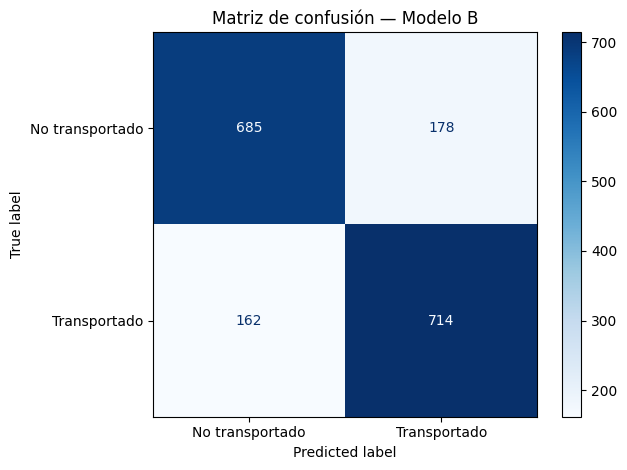

In [61]:
# =====================================================
#  — EVALUACIÓN DEL MODELO B
# =====================================================

# Seleccionar modelo
mejor_modelo = modelos["B - Simple"]

# Generar predicciones de validación
probabilidades = mejor_modelo.predict(
    X_val_pre,
    verbose=0
).ravel()

predicciones = (
    probabilidades >= 0.5
).astype(int)

# Reporte de clasificación
print("REPORTE DEL MODELO B")
print(
    classification_report(
        y_val,
        predicciones,
        target_names=[
            "No transportado",
            "Transportado"
        ]
    )
)

# Matriz de confusión
matriz = confusion_matrix(
    y_val,
    predicciones
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=[
        "No transportado",
        "Transportado"
    ]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Matriz de confusión — Modelo B")
plt.tight_layout()
plt.show()

## — Evaluación del Modelo B

Se evaluó el Modelo B, cuya arquitectura está formada por 28 características de entrada, una capa oculta de 16 neuronas y una neurona de salida.

El modelo obtuvo un accuracy de 80.45% y un F1-score de 80.77%.

Al analizar la matriz de confusión, encontramos que clasificó correctamente a 685 pasajeros no transportados y 714 pasajeros transportados.

Por otra parte, registró 178 falsos positivos y 162 falsos negativos. En total, realizó 1,399

In [64]:
# =====================================================
# — PREPARACIÓN DEL MODELO DEFINITIVO
# =====================================================


# Recuperar las 13 variables predictoras originales
X_final = df_train.drop(
    columns=["Transported", "TotalGastos"],
    errors="ignore"
).copy()

y_final = df_train["Transported"].astype(int).copy()

# Ingeniería de características
X_final_fe = crear_caracteristicas(X_final)

# Crear un preprocesador nuevo
preprocesador_final = clone(preprocesador)

# Ajustar utilizando los datos etiquetados completos
X_final_pre = preprocesador_final.fit_transform(
    X_final_fe
)

# Transformar test con el mismo preprocesador
X_test_final_fe = crear_caracteristicas(df_test)

X_test_final_pre = preprocesador_final.transform(
    X_test_final_fe
)

print("Entrenamiento:", X_final_pre.shape)
print("Prueba final:", X_test_final_pre.shape)

Entrenamiento: (8693, 28)
Prueba final: (4277, 28)


In [65]:
# =====================================================
# — ENTRENAMIENTO DEL MODELO DEFINITIVO
# =====================================================


#  Recuperar la mejor época del Modelo B
historial_b = historiales["B - Simple"]

mejor_epoca_b = (
    np.argmin(historial_b.history["val_loss"]) + 1
)

print("Mejor época del Modelo B:", mejor_epoca_b)

#  Configurar reproducibilidad
tf.keras.utils.set_random_seed(42)

#  Construir el modelo definitivo
modelo_final = keras.Sequential([
    layers.Input(shape=(X_final_pre.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

#  Compilar el modelo
modelo_final.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

#  Entrenar con los 8,693 pasajeros
historial_final = modelo_final.fit(
    X_final_pre,
    y_final,
    epochs=mejor_epoca_b,
    batch_size=32,
    verbose=1
)

print("\nENTRENAMIENTO DEFINITIVO COMPLETADO")

print("Épocas ejecutadas:",
      len(historial_final.history["loss"]))

print("Accuracy final de entrenamiento:",
      round(historial_final.history["accuracy"][-1], 4))

print("Loss final de entrenamiento:",
      round(historial_final.history["loss"][-1], 4))

Mejor época del Modelo B: 59
Epoch 1/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7557 - loss: 0.5244
Epoch 2/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7859 - loss: 0.4482
Epoch 3/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7942 - loss: 0.4302
Epoch 4/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7973 - loss: 0.4216
Epoch 5/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8014 - loss: 0.4163
Epoch 6/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8019 - loss: 0.4126
Epoch 7/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8024 - loss: 0.4098
Epoch 8/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8050 - loss: 0.4074
Epoch 9/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8072 - loss: 0.4053
Epoch 10/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8075 - loss: 0.4036
Epoch 11/59
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8078 - loss: 0.4020
Epoch 12/59
272/272 ━━━

##  — Resultados del entrenamiento definitivo

Se entrenó el modelo definitivo utilizando los 8,693 pasajeros etiquetados del conjunto `train.csv`.

La arquitectura seleccionada fue una red neuronal multicapa con 28 características de entrada, una capa oculta de 16 neuronas con activación ReLU y una neurona de salida con activación sigmoide.

El entrenamiento se realizó durante 59 épocas, utilizando el optimizador Adam y la función de pérdida Binary Crossentropy.

Al finalizar, el modelo obtuvo un accuracy de entrenamiento de 81.64% y una pérdida de 0.3801.

Durante el entrenamiento observamos una disminución progresiva de la función de pérdida, lo que indica que la red neuronal logró ajustar sus parámetros y aprender patrones de los datos.

### Conclusión

El modelo definitivo fue entrenado correctamente utilizando todos los registros etiquetados disponibles.

Aunque el accuracy de entrenamiento alcanzó el 81.64%, este resultado no representa directamente su capacidad de generalización. Para evaluar ese aspecto utilizamos previamente un conjunto de validación, donde el Modelo B obtuvo un accuracy de 80.45%.

Con el modelo entrenado, podemos continuar con la generación de predicciones para los 4,277 pasajeros del conjunto de prueba.

In [66]:
# =====================================================
# — PREDICCIONES FINALES
# =====================================================



#  Generar probabilidades
probabilidades_test = modelo_final.predict(
    X_test_final_pre,
    verbose=0
).ravel()

#  Convertir probabilidades en clases
predicciones_test = (
    probabilidades_test >= 0.5
).astype(bool)

#  Crear archivo de entrega
submission = pd.DataFrame({
    "PassengerId": df_test["PassengerId"],
    "Transported": predicciones_test
})

print("=" * 55)
print("RESULTADOS DE LAS PREDICCIONES")
print("=" * 55)

print("Total de predicciones:", len(submission))

print("\nDistribución de predicciones:")
display(submission["Transported"].value_counts())

print("\nPrimeras 10 predicciones:")
display(submission.head(10))

RESULTADOS DE LAS PREDICCIONES
Total de predicciones: 4277

Distribución de predicciones:


,count
Transported,
True,2206
False,2071



Primeras 10 predicciones:


,PassengerId,Transported
0,0013_01,False
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,False
5,0027_01,True
6,0029_01,True
7,0032_01,True
8,0032_02,True
9,0033_01,False


In [67]:
# =====================================================
#  — VALIDACIÓN DE SUBMISSION
# =====================================================

# Verificar dimensiones
assert submission.shape == (4277, 2)

# Verificar columnas
assert submission.columns.tolist() == [
    "PassengerId",
    "Transported"
]

# Verificar identificadores
assert submission["PassengerId"].equals(
    df_test["PassengerId"]
)

# Verificar valores faltantes
assert submission.isnull().sum().sum() == 0

# Verificar tipo booleano
assert submission["Transported"].dtype == bool

print("Validaciones completadas correctamente.")

Validaciones completadas correctamente.


In [68]:
# =====================================================
# — EXPORTAR PREDICCIONES
# =====================================================

submission.to_csv(
    "submission.csv",
    index=False
)

print("Archivo submission.csv generado correctamente.")

# Descargar desde Google Colab
from google.colab import files

files.download("submission.csv")

Archivo submission.csv generado correctamente.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>